# Customer Segmentation — Step-by-Step Machine Learning Pipeline

**Goal:** Use KMeans to discover customer segments, then optionally train a **Random Forest classifier** to reproduce those segment labels.

**Workflow:** Load data → Inspect and clean → Feature engineering → EDA → Train/test split → Preprocess → PCA → Choose K → KMeans → Segment profiles → Classifier (`GridSearchCV`, accuracy only) → Save **only the classifier pipeline**.

**Training rule:** Fit preprocessing, PCA, and KMeans using the **training data**. The held-out test data is not used to select models or hyperparameters.

**Important:** Cluster IDs are **pseudo-labels**, not real business targets such as `Response`. Classifier accuracy means agreement with KMeans, **not marketing outcome accuracy**.

**Before running:** Put `marketing_campaign (1).csv` beside this notebook and run from top to bottom.

## 1. Setup
### 1.1 Import libraries

Import the tools we need for reading the dataset, plotting, preprocessing, clustering, evaluation and saving results. No data is processed here.

In [1]:
from pathlib import Path
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import accuracy_score, silhouette_score
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, RobustScaler

### 1.2 Locate the dataset

Look for the CSV in a few common locations. This makes the notebook usable locally and in Colab without changing the ML logic.

In [2]:
possible_files = [
    Path('marketing_campaign (1).csv'),
    Path('marketing_campaign.csv'),
    Path('/content/marketing_campaign (1).csv'),
    Path('/content/marketing_campaign.csv'),
    Path('/mnt/data/marketing_campaign (1).csv'),
]
csv_file = next((p for p in possible_files if p.exists()), None)
if csv_file is None:
    raise FileNotFoundError('Put marketing_campaign (1).csv beside this notebook.')
print('Dataset:', csv_file)

Dataset: marketing_campaign (1).csv


### 1.3 Load the raw data

Read the marketing campaign CSV into a Pandas DataFrame. The file uses a **tab** separator, so we set `sep="\t"`.

In [3]:
df = pd.read_csv(csv_file, sep='\t')

### 1.4 Preview the data

See the number of rows and columns and the first five customers. This confirms that loading worked.

In [4]:
print('Rows and columns:', df.shape)
display(df.head())

Rows and columns: (2240, 29)


,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
0,5524,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,...,7,0,0,0,0,0,0,3,11,1
1,2174,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,...,5,0,0,0,0,0,0,3,11,0
2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,...,4,0,0,0,0,0,0,3,11,0
3,6182,1984,Graduation,Together,26646.0,1,0,10-02-2014,26,11,...,6,0,0,0,0,0,0,3,11,0
4,5324,1981,PhD,Married,58293.0,1,0,19-01-2014,94,173,...,5,0,0,0,0,0,0,3,11,0


## 2. Understand data quality
### 2.1 Inspect columns and types

`info()` shows each column, its data type and how many values are present. This helps spot dates stored as text.

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2240 entries, 0 to 2239
Data columns (total 29 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   ID                   2240 non-null   int64  
 1   Year_Birth           2240 non-null   int64  
 2   Education            2240 non-null   str    
 3   Marital_Status       2240 non-null   str    
 4   Income               2216 non-null   float64
 5   Kidhome              2240 non-null   int64  
 6   Teenhome             2240 non-null   int64  
 7   Dt_Customer          2240 non-null   str    
 8   Recency              2240 non-null   int64  
 9   MntWines             2240 non-null   int64  
 10  MntFruits            2240 non-null   int64  
 11  MntMeatProducts      2240 non-null   int64  
 12  MntFishProducts      2240 non-null   int64  
 13  MntSweetProducts     2240 non-null   int64  
 14  MntGoldProds         2240 non-null   int64  
 15  NumDealsPurchases    2240 non-null   int64  
 16 

### 2.2 Check missing values

Count null values in each column. We only **inspect** missing data here; `Income` will be filled using training data later.

In [6]:
display(df.isna().sum()[df.isna().sum() > 0])

Income    24
dtype: int64

### 2.3 Check duplicates

Count repeated rows to see whether duplicate customer records need to be removed.

In [7]:
print('Duplicate rows:', df.duplicated().sum())

Duplicate rows: 0


### 2.4 Review numerical statistics

Check typical values and ranges. Very large or impossible values may indicate data quality problems.

In [8]:
display(df.describe().round(1))

,ID,Year_Birth,Income,Kidhome,Teenhome,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,...,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
count,2240.0,2240.0,2216.0,2240.0,2240.0,2240.0,2240.0,2240.0,2240.0,2240.0,...,2240.0,2240.0,2240.0,2240.0,2240.0,2240.0,2240.0,2240.0,2240.0,2240.0
mean,5592.2,1968.8,52247.3,0.4,0.5,49.1,303.9,26.3,167.0,37.5,...,5.3,0.1,0.1,0.1,0.1,0.0,0.0,3.0,11.0,0.1
std,3246.7,12.0,25173.1,0.5,0.5,29.0,336.6,39.8,225.7,54.6,...,2.4,0.3,0.3,0.3,0.2,0.1,0.1,0.0,0.0,0.4
min,0.0,1893.0,1730.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,3.0,11.0,0.0
25%,2828.2,1959.0,35303.0,0.0,0.0,24.0,23.8,1.0,16.0,3.0,...,3.0,0.0,0.0,0.0,0.0,0.0,0.0,3.0,11.0,0.0
50%,5458.5,1970.0,51381.5,0.0,0.0,49.0,173.5,8.0,67.0,12.0,...,6.0,0.0,0.0,0.0,0.0,0.0,0.0,3.0,11.0,0.0
75%,8427.8,1977.0,68522.0,1.0,1.0,74.0,504.2,33.0,232.0,50.0,...,7.0,0.0,0.0,0.0,0.0,0.0,0.0,3.0,11.0,0.0
max,11191.0,1996.0,666666.0,2.0,2.0,99.0,1493.0,199.0,1725.0,259.0,...,20.0,1.0,1.0,1.0,1.0,1.0,1.0,3.0,11.0,1.0


## 3. Clean data and create useful features
### 3.1 Remove duplicate rows

Remove exact duplicates so identical records do not receive extra weight in clustering.

In [9]:
df = df.drop_duplicates().copy()

### 3.2 Convert customer dates

Convert `Dt_Customer` from day-month-year text to real dates. Invalid dates become missing (`NaT`).

In [10]:
df['Dt_Customer'] = pd.to_datetime(df['Dt_Customer'], format='%d-%m-%Y', errors='coerce')

### 3.3 Remove invalid dates

A missing join date prevents us from calculating tenure. Drop only rows with an invalid date.

In [11]:
df = df.dropna(subset=['Dt_Customer']).copy()

### 3.4 Set a historical reference date

Use the latest join date in this historical dataset as a fixed snapshot. This avoids using today's date for records from 2012–2014.

In [12]:
snapshot_date = df['Dt_Customer'].max()
print('Historical snapshot:', snapshot_date.date())

Historical snapshot: 2014-06-29


### 3.5 Create customer age

Estimate age at the historical snapshot using `Year_Birth`.

In [13]:
df['Age'] = snapshot_date.year - df['Year_Birth']

### 3.6 Create customer tenure

`Tenure_Days` measures how long a customer has been registered, relative to the snapshot.

In [14]:
df['Tenure_Days'] = (snapshot_date - df['Dt_Customer']).dt.days

### 3.7 Remove clearly unrealistic records

Apply simple fixed quality rules: ages 18–100 and income no higher than 200,000. **Keep missing income** for later training-only imputation. The income threshold is dataset-specific, not a universal rule.

In [15]:
rows_before = len(df)
df = df[
    df['Age'].between(18, 100)
    & (df['Income'].isna() | (df['Income'] <= 200_000))
].copy()
print('Rows removed:', rows_before - len(df))

Rows removed: 4


### 3.8 Create total spending

Add the amounts spent in six product categories to get one readable `Total_Spending` feature. The original category amounts are not used again as separate model features.

In [16]:
spending_cols = [
    'MntWines', 'MntFruits', 'MntMeatProducts',
    'MntFishProducts', 'MntSweetProducts', 'MntGoldProds'
]
df['Total_Spending'] = df[spending_cols].sum(axis=1)

### 3.9 Create total purchases

Add purchase counts across deal, website, catalog and store purchases into one `Total_Purchases` feature.

In [17]:
purchase_cols = [
    'NumDealsPurchases', 'NumWebPurchases',
    'NumCatalogPurchases', 'NumStorePurchases'
]
df['Total_Purchases'] = df[purchase_cols].sum(axis=1)

### 3.10 Verify engineered features

Check a few customer rows after the cleaning and feature creation steps.

In [18]:
display(df[['Income', 'Age', 'Tenure_Days', 'Total_Spending', 'Total_Purchases']].head())

,Income,Age,Tenure_Days,Total_Spending,Total_Purchases
0,58138.0,57,663,1617,25
1,46344.0,60,113,27,6
2,71613.0,49,312,776,21
3,26646.0,30,139,53,8
4,58293.0,33,161,422,19


## 4. Exploratory Data Analysis (EDA)
### 4.1 Plot numerical features

Histograms show the distribution of income, age, spending and purchases. This is **exploration only**: we do not fit any scalers or imputers.

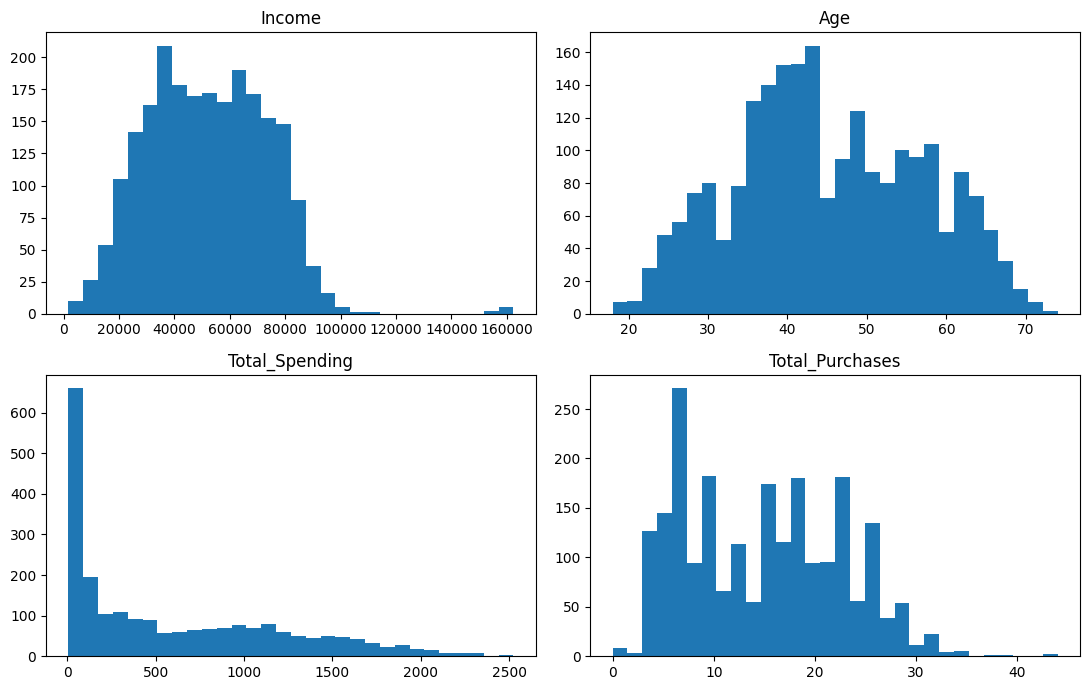

In [19]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for ax, col in zip(axes.flat, ['Income', 'Age', 'Total_Spending', 'Total_Purchases']):
    ax.hist(df[col].dropna(), bins=30)
    ax.set_title(col)
plt.tight_layout()
plt.show()

### 4.2 Plot categorical features

Bar charts show customer counts by `Education` and `Marital_Status`.

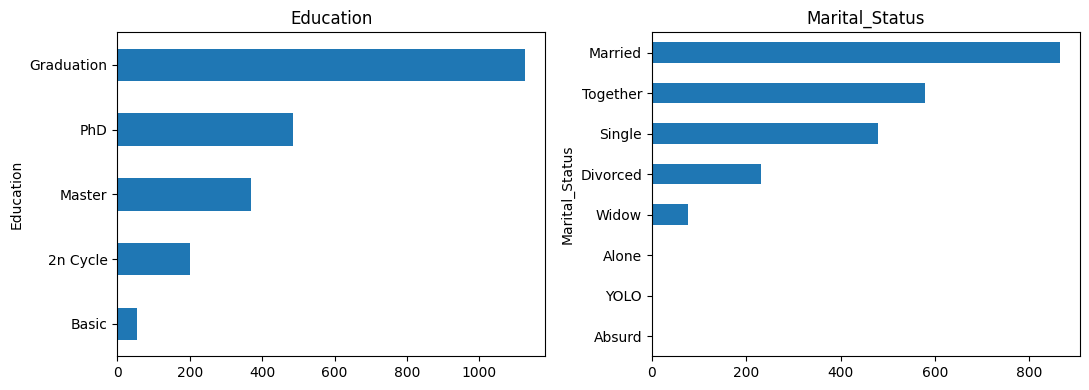

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, col in zip(axes, ['Education', 'Marital_Status']):
    df[col].value_counts().sort_values().plot.barh(ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

## 5. Select features and split the data
### 5.1 Define the feature columns

Select simple demographic and purchasing features for clustering. Avoid IDs, constant columns, raw dates, `Response`, and individual amount/count columns already represented by totals.

In [21]:
num_cols = [
    'Income', 'Age', 'Tenure_Days', 'Kidhome', 'Teenhome',
    'Recency', 'NumWebVisitsMonth', 'Total_Spending', 'Total_Purchases'
]
cat_cols = ['Education', 'Marital_Status']

### 5.2 Create the feature table

`X` contains only the columns the model should use. Clustering has **no true target `y`**.

In [22]:
X = df[num_cols + cat_cols].copy()

### 5.3 Create train/test sets

Hold back 20% of customers for evaluation. **Do this before fitting** missing-value replacements, scaling, PCA, or clustering.

In [23]:
X_train, X_test = train_test_split(X, test_size=0.20, random_state=42)
print('Train:', X_train.shape, '| Test:', X_test.shape)

Train: (1788, 11) | Test: (448, 11)


## 6. Preprocess the features
### 6.1 Prepare numerical features

The numerical pipeline will replace missing values with the **training median** and then apply `RobustScaler`, which is less sensitive to extreme values.

In [24]:
numeric_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', RobustScaler())
])

### 6.2 Prepare categorical features

For categories, replace any missing entries with the most frequent training category, then convert category names to one-hot numeric columns.

In [25]:
categorical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

### 6.3 Combine both preprocessing paths

`ColumnTransformer` sends numeric columns through the numerical pipeline and categorical columns through the categorical pipeline.

In [26]:
preprocessor = ColumnTransformer([
    ('num', numeric_pipeline, num_cols),
    ('cat', categorical_pipeline, cat_cols)
])

### 6.4 Fit preprocessing on the training set

`fit_transform` **learns medians, scale values, and categories from `X_train` only**, then applies those rules to training rows.

In [27]:
X_train_prepared = preprocessor.fit_transform(X_train)

### 6.5 Transform the test set (no fitting)

`transform` applies the **same learned rules** to `X_test`. We never call `fit()` on the test data.

In [28]:
X_test_prepared = preprocessor.transform(X_test)

### 6.6 Check the prepared shapes

Verify that both datasets now have the same number of numeric/encoded columns.

In [29]:
print('Train:', X_train_prepared.shape, '| Test:', X_test_prepared.shape)

Train: (1788, 22) | Test: (448, 22)


## 7. PCA dimensionality reduction
### 7.1 Learn PCA from training data

PCA creates fewer combined features while preserving about **95% of the training variance**. It is trained only using preprocessed training customers.

In [30]:
pca = PCA(n_components=0.95, random_state=42)
X_train_pca = pca.fit_transform(X_train_prepared)

### 7.2 Apply the same PCA to test data

Use the PCA directions learned from training data. Do **not** fit PCA a second time.

In [31]:
X_test_pca = pca.transform(X_test_prepared)

### 7.3 Review retained dimensions

Compare the number of features before and after PCA, plus the proportion of variance retained.

In [32]:
print('Before PCA:', X_train_prepared.shape[1])
print('After PCA:', X_train_pca.shape[1])
print('Variance retained:', round(pca.explained_variance_ratio_.sum(), 3))

Before PCA: 22
After PCA: 13
Variance retained: 0.954


## 8. Find a suitable number of clusters
### 8.1 Try several K values

Fit candidate KMeans models for `K=2...8` **on training data only**. Record inertia for the elbow method and silhouette scores for separation quality.

In [33]:
k_results = []
for k in range(2, 9):
    candidate = KMeans(n_clusters=k, n_init=10, random_state=42)
    labels = candidate.fit_predict(X_train_pca)
    k_results.append({
        'K': k,
        'Inertia': candidate.inertia_,
        'Silhouette': silhouette_score(X_train_pca, labels)
    })

### 8.2 Put K scores into a table

Make it easy to compare the results for different numbers of clusters.

In [34]:
k_scores = pd.DataFrame(k_results)
display(k_scores.round(3))

,K,Inertia,Silhouette
0,2,6147.749,0.198
1,3,5630.818,0.148
2,4,5263.192,0.123
3,5,5077.296,0.113
4,6,4885.816,0.113
5,7,4731.087,0.100
6,8,4584.357,0.102


### 8.3 Plot the elbow curve

The inertia plot helps identify where adding more clusters stops significantly reducing within-cluster distances.

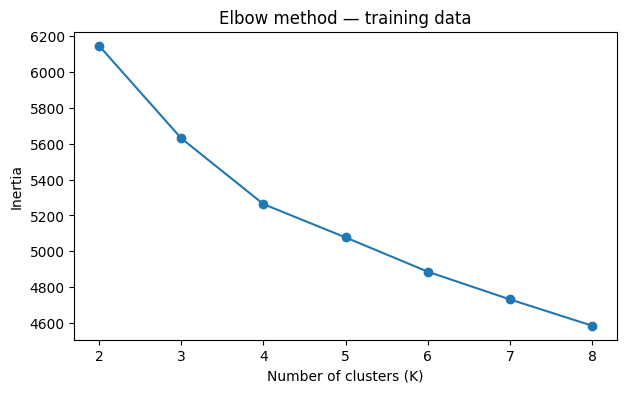

In [35]:
plt.figure(figsize=(7, 4))
plt.plot(k_scores['K'], k_scores['Inertia'], marker='o')
plt.xlabel('Number of clusters (K)')
plt.ylabel('Inertia')
plt.title('Elbow method — training data')
plt.show()

### 8.4 Plot silhouette scores

A higher silhouette generally means clusters are better separated in the selected PCA feature space.

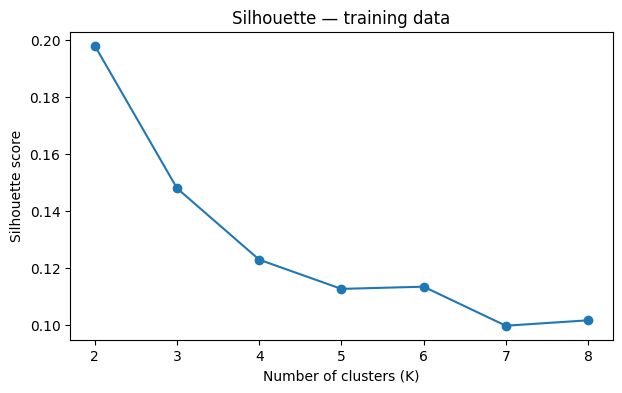

In [36]:
plt.figure(figsize=(7, 4))
plt.plot(k_scores['K'], k_scores['Silhouette'], marker='o')
plt.xlabel('Number of clusters (K)')
plt.ylabel('Silhouette score')
plt.title('Silhouette — training data')
plt.show()

### 8.5 Select K using training scores

Choose the K with the best **training silhouette**. No test data is used for choosing K. Business interpretation may justify selecting a different K later.

In [37]:
best_k = int(k_scores.loc[k_scores['Silhouette'].idxmax(), 'K'])
print('Selected number of clusters:', best_k)

Selected number of clusters: 2


## 9. Train and evaluate KMeans
### 9.1 Fit the final clustering model

Fit KMeans once on **training PCA features** with the selected number of clusters. `labels_` gives the training assignments.

In [38]:
kmeans = KMeans(n_clusters=best_k, n_init=10, random_state=42)
kmeans.fit(X_train_pca)
train_clusters = kmeans.labels_

### 9.2 Predict clusters for held-out customers

`predict()` assigns test customers to the closest **already learned** centroid. There is no fitting on test customers.

In [39]:
test_clusters = kmeans.predict(X_test_pca)

### 9.3 Evaluate cluster separation

Compare train/test silhouette scores. A silhouette score is **not accuracy** and does not prove that the groups are useful for a marketing goal.

In [40]:
print('Training silhouette:', round(silhouette_score(X_train_pca, train_clusters), 3))
print('Test silhouette:', round(silhouette_score(X_test_pca, test_clusters), 3))

Training silhouette: 0.198
Test silhouette: 0.208


### 9.4 Check cluster sizes

Count training customers per cluster to spot very tiny or imbalanced groups.

In [41]:
display(pd.Series(train_clusters, name="Cluster").value_counts().sort_index())

Cluster
0    922
1    866
Name: count, dtype: int64

## 10. Interpret the customer segments

### 10.1 Collect training customer labels

Attach each training customer index to its KMeans cluster label. We use these labels **only for describing the segments**, not for training the classifier.

In [42]:
cluster_labels = pd.Series(train_clusters, index=X_train.index)

### 10.2 Combine training and test labels

Add the predicted test labels to the training labels, keeping each customer index. This is **for reporting only**, with no new fitting.

In [43]:
cluster_labels = pd.concat([
    cluster_labels, pd.Series(test_clusters, index=X_test.index)
])

### 10.3 Add labels to the reporting table

Align labels by customer index so each row gets the correct segment.

In [44]:
df['Cluster'] = cluster_labels.astype(int)

### 10.4 Create a cluster profile

Summarize the mean income, age, spending, purchases and activity for each cluster. We use original business units rather than scaled PCA values.

In [45]:
cluster_profile = df.groupby('Cluster')[
    ['Income', 'Age', 'Total_Spending', 'Total_Purchases',
     'Recency', 'NumWebVisitsMonth']
].mean().round(1)
cluster_profile.insert(0, 'Customers', df['Cluster'].value_counts().sort_index())
display(cluster_profile)

,Customers,Income,Age,Total_Spending,Total_Purchases,Recency,NumWebVisitsMonth
Cluster,,,,,,,
0,1160,35578.5,42.6,136.6,9.2,48.4,6.6
1,1076,69600.4,47.8,1112.0,21.0,49.9,3.9


### 10.5 Visualize clusters in two PCA dimensions

Plot training customers using the first two PCA components. **The plot is only a 2D view**; KMeans was trained using all retained PCA components.

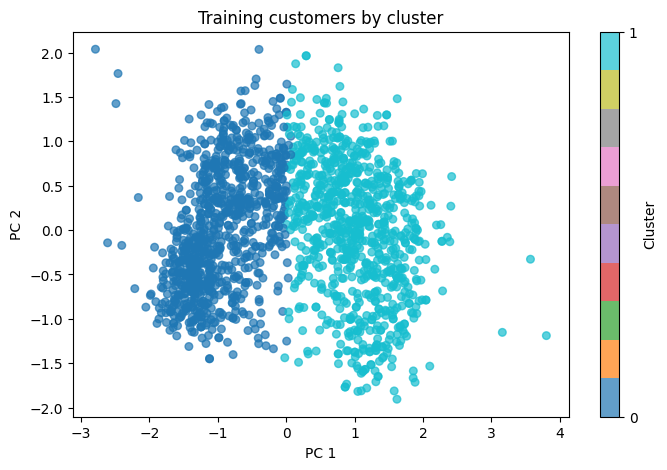

In [46]:
plt.figure(figsize=(8, 5))
points = plt.scatter(X_train_pca[:, 0], X_train_pca[:, 1],
                     c=train_clusters, cmap='tab10', s=30, alpha=0.7)
plt.colorbar(points, label='Cluster', ticks=range(best_k))
plt.xlabel('PC 1')
plt.ylabel('PC 2')
plt.title('Training customers by cluster')
plt.show()

## 11. Train a classifier to reproduce the clusters

KMeans has already generated our **pseudo-labels** (`train_clusters` and `test_clusters`). We will train **one Random Forest classifier**, use `GridSearchCV` to choose its parameters, and save only its complete classifier pipeline. Preprocessing is inside this pipeline, so cross-validation can fit preprocessing separately for each fold.

### 11.1 Choose the classifier

Create a basic Random Forest model. There is no need for a loop comparing multiple classifiers.

In [47]:
classifier = RandomForestClassifier(random_state=42)

### 11.2 Build the classifier pipeline

Combine preprocessing with the classifier. This makes the saved model usable on feature tables like `X_test`, without separately calling the scaler or encoder.

In [48]:
classifier_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model', classifier)
])

### 11.3 Choose a small parameter grid

Try only two options for each Random Forest setting to keep `GridSearchCV` fast and understandable.

In [49]:
param_grid = {
    'model__n_estimators': [50, 100],
    'model__max_depth': [None, 10]
}

### 11.4 Set up GridSearchCV

Use three training folds and **accuracy** as the only classification scoring metric. `GridSearchCV` does not access `X_test`.

In [50]:
grid_search = GridSearchCV(
    classifier_pipeline, param_grid, cv=3, scoring='accuracy'
)

### 11.5 Fit on training data

Train on original feature columns (`X_train`) and KMeans training labels (`train_clusters`). The preprocessing inside the pipeline is refitted per training fold.

In [51]:
grid_search.fit(X_train, train_clusters)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'model__max_depth': [None, 10], 'model__n_estimators': [50, 100]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'accuracy'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",3
,"verbose verbose: intControls the verbosity: the higher, the more messages.- >1 : the computation time for each fold and parameter candidate is displayed;- >2 : the score is also 

### 11.6 Review cross-validation accuracy

This score measures how well the classifier reproduces KMeans labels in training cross-validation.

In [52]:
print('Best CV accuracy:', round(grid_search.best_score_, 3))

Best CV accuracy: 0.975


### 11.7 Review selected parameters

Display the settings that gave the highest cross-validation accuracy.

In [53]:
print(grid_search.best_params_)

{'model__max_depth': 10, 'model__n_estimators': 100}


### 11.8 Keep the best classifier pipeline

`best_estimator_` contains the **fitted preprocessing and Random Forest classifier** together. We do not need to save KMeans or PCA for classifier predictions.

In [54]:
best_classifier = grid_search.best_estimator_

## 12. Test the classifier

### 12.1 Predict held-out customer clusters

Use only the classifier pipeline. It transforms the test features internally and returns predicted segment IDs.

In [55]:
predicted_clusters = best_classifier.predict(X_test)

### 12.2 Calculate test accuracy

Compare predictions with `test_clusters` assigned by the training-fitted KMeans. This is **agreement with KMeans**, not accuracy against actual marketing outcomes.

In [56]:
print('Test accuracy:', round(accuracy_score(test_clusters, predicted_clusters), 3))

Test accuracy: 0.973


## 13. Save and reuse the classifier pipeline

### 13.1 Save only the classifier pipeline

This one file contains the fitted encoder, imputer, scaler and Random Forest. **The segmentation pipeline is not saved.**

In [57]:
joblib.dump(best_classifier, 'cluster_classifier.joblib')

['cluster_classifier.joblib']

### 13.2 Load the classifier pipeline

Load the same fitted pipeline independently, without loading KMeans or PCA.

In [58]:
loaded_classifier = joblib.load('cluster_classifier.joblib')

### 13.3 Test the loaded classifier

Predict segment IDs for a few held-out rows. The input must include the same feature columns as `X_train` (including the engineered `Age`, `Tenure_Days`, `Total_Spending`, `Total_Purchases`).

In [59]:
print('Predicted clusters:', loaded_classifier.predict(X_test.head()))

Predicted clusters: [0 0 1 1 1]


### 13.4 Export cluster profiles

Save the summary table for reports. This CSV is **not** a model or pipeline.

In [60]:
cluster_profile.to_csv('cluster_profiles.csv')

In [62]:
import pickle

bundle = {
    'model': best_classifier,   # preprocessing + Random Forest pipeline
    'meta': {
        'snapshot_date': snapshot_date.to_pydatetime(),
        'num_cols': num_cols,
        'cat_cols': cat_cols,
        'education_options': sorted(df['Education'].dropna().unique().tolist()),
        'marital_options': sorted(df['Marital_Status'].dropna().unique().tolist()),
        'cluster_profile': cluster_profile,
        'input_ranges': {
            'Income': (0, 200_000, float(df['Income'].median())),
            'Age': (18, 100, int(df['Age'].median())),
            'Recency': (0, 99, int(df['Recency'].median())),
            'NumWebVisitsMonth': (0, 20, int(df['NumWebVisitsMonth'].median())),
        },
    },
}
with open('cluster_classifier.pkl', 'wb') as f:
    pickle.dump(bundle, f)

## Finished

**Workflow:** data → cleaning → features → split → training-only preprocessing/PCA → KMeans labels → train-only GridSearchCV (accuracy) → classifier test accuracy → save and load **only** `cluster_classifier.joblib`.

**For new data:** The saved classifier expects the same `X_train` columns. It handles missing-value imputation, scaling, and encoding internally, but **Age, Tenure_Days, Total_Spending and Total_Purchases must be calculated first**, using consistent rules (including the historical reference date). KMeans is needed only if you want to produce or compare against its original labels, not to run the saved classifier.